# Gradient Descent

In the previous chapter, we have seen that the **training phase** of a Neural Network (and, more generally, of any Machine Learning model) can be expressed as an **optimization problem**: given a loss function

$$
\mathcal{L}(\Theta) = \frac{1}{N}\sum_{i=1}^N \ell(\Theta; x^{(i)}, y^{(i)}),
$$

our goal is to find

$$
\Theta^* = \arg\min_\Theta \, \mathcal{L}(\Theta).
$$

For very simple models (like linear regression with the MSE loss), this minimization problem admits a closed-form solution. In general, however, the loss function is **non-linear, high-dimensional, and non-convex**, making analytic solutions impossible. We therefore rely on **iterative optimization algorithms**, the most fundamental of which is **Gradient Descent**.

Since the theory of optimization does not depend on the fact that we are training a Machine Learning model, in the first part of this chapter we will consider a generic function $f: \mathbb{R}^n \to \mathbb{R}$ of a variable $x \in \mathbb{R}^n$. At the end of the chapter, we will go back to our Neural Network, with $f = \mathcal{L}$ and $x = \Theta$.

```{warning}
In this chapter, $x$ denotes the **optimization variable** (i.e. the parameters of the model), and not the input of the model, as it was in the previous chapters.
```

## Optimization problems

Consider a function $f: \mathbb{R}^n \to \mathbb{R}$, named **objective function**. Given a set of *admissible solutions* $\Omega \subseteq \mathbb{R}^n$, an optimization problem is a problem of the form

$$
\min_{x \in \Omega} f(x).
$$

If $\Omega = \mathbb{R}^n$, we say that the optimization problem is **unconstrained**. If $\Omega \subset \mathbb{R}^n$, the problem is **constrained**. In the following, we will always assume $\Omega = \mathbb{R}^n$, i.e. the unconstrained setup, which is the one of interest for training Neural Networks.

We need to be precise about what we mean by "solution" of an optimization problem:

- $x^* \in \mathbb{R}^n$ is a **global minimum** of $f$ if $f(x^*) \leq f(x)$ for any $x \in \mathbb{R}^n$.
- $x^* \in \mathbb{R}^n$ is a **local minimum** of $f$ if there exists a neighborhood $\mathcal{U}$ of $x^*$ such that $f(x^*) \leq f(x)$ for any $x \in \mathcal{U}$.
- If the inequalities above are strict for any $x \neq x^*$, we talk about **strict** global (local) minimum.

Clearly, any global minimum is also a local minimum, but the opposite is not true in general. Ideally, we would like to find a global minimum but, as we will see, the algorithms we are going to introduce are only able (in general) to find **local** minima.

## Convexity
A common assumption in optimization is _convexity_. By definition, a function $f: \mathbb{R}^n \to \mathbb{R}$ is **convex** if

$$
f(tx_1 + (1-t)x_2) \leq tf(x_1) + (1-t)f(x_2), \quad \forall x_1, x_2 \in \mathbb{R}^n, \quad \forall t \in [0, 1],
$$

i.e. if the segment joining any two points of the graph of $f$ lies above the graph itself. If the inequality is strict for any $x_1 \neq x_2$ and $t \in (0, 1)$, then $f$ is said to be **strictly convex**.

![](./fig/convexity.png)

The importance of convex functions in optimization is due to the following properties:

- If $f$ is convex, then every local minimum of $f$ is also a **global minimum**, and the set of global minima is a convex set (the $n$-dimensional extension of the concept of _interval_).
- If $f$ is strictly convex, then it has **at most one** global minimum.

On the other side, if a function is non-convex (_NOTE:_ the opposite of convex is **not** concave), then there can be multiple distinct minimum points, some of which are _local minima_ while others are _global minima_.

![](./fig/non_convexity.png)

When $f$ is differentiable (twice differentiable), convexity can be equivalently characterized by its gradient (Hessian):

- **First-order characterization:** $f$ is convex if and only if

  $$
  f(y) \geq f(x) + \nabla f(x)^T (y - x), \quad \forall x, y \in \mathbb{R}^n,
  $$

  i.e. the tangent plane at any point lies *below* the graph of $f$.

- **Second-order characterization:** $f$ is convex if and only if the Hessian matrix $\nabla^2 f(x)$ is **positive semi-definite** for any $x \in \mathbb{R}^n$.

**Example.** Consider the quadratic function $f(x) = \frac{1}{2} x^T A x - b^T x$, with $A \in \mathbb{R}^{n \times n}$ symmetric. Its Hessian is $\nabla^2 f(x) = A$, therefore $f$ is convex if and only if $A$ is positive semi-definite, and strictly convex if $A$ is positive definite. As a consequence, the MSE loss of a linear regression model, $\mathcal{L}(\Theta) = \frac{1}{N} \| X\Theta - Y \|_2^2$, is always convex (check it!).

```{important}
The loss function of a Neural Network is (almost always) **non-convex**. To convince yourself, consider an MLP with one hidden layer, and assume $\Theta^*$ is a global minimum of $\mathcal{L}$. If we swap two neurons of the hidden layer (i.e. we swap two rows of $W^1$ and $b^1$, and the corresponding two columns of $W^2$), the network computes exactly the same function, therefore the swapped parameters $\tilde{\Theta}^*$ are a global minimum as well. However, the midpoint $\frac{1}{2}(\Theta^* + \tilde{\Theta}^*)$ corresponds to a network where the two neurons are identical, which, in general, is **not** a minimum. This contradicts the convexity.
```

## Gradient, Hessian and optimality conditions

Recall that, for a differentiable function $f: \mathbb{R}^n \to \mathbb{R}$, the **gradient** of $f$ at $x$ is the vector of its partial derivatives:

$$
\nabla f(x) = \begin{bmatrix} \frac{\partial f}{\partial x_1}(x) \\ \vdots \\ \frac{\partial f}{\partial x_n}(x) \end{bmatrix} \in \mathbb{R}^n,
$$

while, if $f$ is twice differentiable, its **Hessian** is the symmetric matrix of its second-order partial derivatives:

$$
\nabla^2 f(x) = \left[ \frac{\partial^2 f}{\partial x_i \partial x_j}(x) \right]_{i, j = 1}^n \in \mathbb{R}^{n \times n}.
$$

### The gradient is the direction of steepest ascent

Given a direction $p \in \mathbb{R}^n$ with $\| p \|_2 = 1$, the **directional derivative** of $f$ at $x$ along $p$ measures how fast $f$ changes when we move from $x$ in the direction $p$:

$$
\frac{\partial f}{\partial p}(x) = \lim_{\alpha \to 0} \frac{f(x + \alpha p) - f(x)}{\alpha} = \nabla f(x)^T p.
$$

By the Cauchy-Schwarz inequality,

$$
- \| \nabla f(x) \|_2 \leq \nabla f(x)^T p \leq \| \nabla f(x) \|_2,
$$

where the right equality holds if and only if $p = \frac{\nabla f(x)}{\| \nabla f(x) \|_2}$, while the left equality holds if and only if $p = - \frac{\nabla f(x)}{\| \nabla f(x) \|_2}$. Therefore:

> The gradient $\nabla f(x)$ points in the direction of **steepest ascent** of $f$ at $x$, while $-\nabla f(x)$ points in the direction of **steepest descent**.

Moreover, if $\nabla f(x)^T p < 0$, then moving along $p$ (for a sufficiently small step) decreases the value of $f$. Any such direction is called a **descent direction**. This simple observation is the basis of all the algorithms we will study.

### Optimality conditions

Most of the algorithms to find the minimum points of a given function $f(x)$ are based on the following properties:

- **First-order necessary condition:** If $f$ is continuously differentiable and $x^*$ is a local minimum of $f$, then

  $$
  \nabla f(x^*) = 0.
  $$

  *Proof (sketch).* If $\nabla f(x^*) \neq 0$, then $p = -\nabla f(x^*)$ is a descent direction, and therefore there are points arbitrarily close to $x^*$ with a smaller value of $f$, which contradicts the local minimality of $x^*$.

- **Second-order necessary condition:** If $f$ is twice continuously differentiable and $x^*$ is a local minimum of $f$, then $\nabla f(x^*) = 0$ and $\nabla^2 f(x^*)$ is **positive semi-definite**.

- **Second-order sufficient condition:** If $f$ is twice continuously differentiable, $\nabla f(x^*) = 0$ and $\nabla^2 f(x^*)$ is **positive definite**, then $x^*$ is a **strict local minimum** of $f$.

The points $x^* \in \mathbb{R}^n$ such that $\nabla f(x^*) = 0$ are called **stationary points** of $f$. Note that the first-order condition is only *necessary*: a stationary point can be a (local) minimum, a (local) maximum or a **saddle point** (a point which is a minimum along some directions and a maximum along others, i.e. where the Hessian is *indefinite*).

![](./fig/minmaxsaddle.png)

The situation is much simpler for convex functions. Indeed:

- **Convex case:** If $f$ is convex and differentiable, then $x^*$ is a global minimum of $f$ **if and only if** $\nabla f(x^*) = 0$.

  *Proof.* By the first-order characterization of convexity, for any $y \in \mathbb{R}^n$, $f(y) \geq f(x^*) + \nabla f(x^*)^T (y - x^*) = f(x^*)$.

Consequently, in the following, we will look for points $x^* \in \mathbb{R}^n$ such that $\nabla f(x^*) = 0$, keeping in mind that, when $f$ is not convex, such a point is not necessarily a global minimum (and not even necessarily a minimum).

> **Exercise:** Compute the stationary points of $f(x) = x_1^2 - x_2^2$ and of $f(x) = x_1^4 + x_2^2$, and classify them using the second-order conditions. Is the second-order sufficient condition satisfied in both cases?

## The Gradient Descent algorithm

The most common algorithm to solve optimization problems is the so-called **Gradient Descent (GD)**. The idea is very simple: since $-\nabla f(x)$ is the direction of steepest descent, if we move from $x$ a little bit along $-\nabla f(x)$, the value of $f$ decreases. Repeating this procedure iteratively, we expect to reach a (local) minimum of $f$.

This leads to the iterative algorithm:

$$
x_{k+1} = x_k - \alpha_k \nabla f(x_k), \quad k = 0, 1, \dots, \texttt{maxit}-1,
$$

where the initial iterate, $x_0 \in \mathbb{R}^n$, is given as input and the **step size** (equivalently, **learning rate**) $\alpha_k > 0$ controls how far we move along the descent direction at each iteration.

Formally, the resulting algorithm reads:

**Input**: initial iterate $x_0$, step sizes $\{ \alpha_k \}_k$, stopping criterion.
**Repeat** for $k = 0, 1, \dots$ until the stopping criterion is satisfied:
1. Compute the gradient $\nabla f(x_k)$.
2. Update the iterate: $x_{k+1} = x_k - \alpha_k \nabla f(x_k)$.

```{note}
The gradient descent algorithm is an example of **descent methods**:

$$
x_{k+1} = x_k + \alpha_k p_k, \quad k = 0, 1, \dots, \texttt{maxit}-1,
$$

where the descent direction $p_k$ has to be chosen such that for any $k \in \mathbb{N}$:

$$
\nabla f(x_k)^T p_k < 0.
$$

Since for GD, $p_k = - \nabla f(x_k)$, then the condition above is always satisfied (unless we are already in a stationary point):

$$
\nabla f(x_k)^T p_k = - \nabla f(x_k)^T \nabla f(x_k) = - \| \nabla f(x_k) \|_2^2 < 0.
$$
```

### Convergence of Gradient Descent

When does GD converge, and how fast? To answer this question, we need an assumption on the regularity of $f$. We say that a differentiable function $f$ is **$L$-smooth** if its gradient is Lipschitz continuous with constant $L > 0$, i.e.

$$
\| \nabla f(x) - \nabla f(y) \|_2 \leq L \| x - y \|_2, \quad \forall x, y \in \mathbb{R}^n.
$$

For twice differentiable functions, this is equivalent to $\| \nabla^2 f(x) \|_2 \leq L$ for any $x$, i.e. the curvature of $f$ is bounded by $L$. A key consequence of $L$-smoothness is the so-called **descent lemma**:

$$
f(y) \leq f(x) + \nabla f(x)^T (y - x) + \frac{L}{2} \| y - x \|_2^2, \quad \forall x, y \in \mathbb{R}^n,
$$

which states that $f$ is bounded from above by a quadratic function. Applying it with $x = x_k$ and $y = x_{k+1} = x_k - \alpha \nabla f(x_k)$, we get:

$$
f(x_{k+1}) \leq f(x_k) - \alpha \| \nabla f(x_k) \|_2^2 + \frac{L \alpha^2}{2} \| \nabla f(x_k) \|_2^2 = f(x_k) - \alpha \left( 1 - \frac{L\alpha}{2} \right) \| \nabla f(x_k) \|_2^2.
$$

Therefore, if $0 < \alpha < \frac{2}{L}$, the value of $f$ **decreases** at every iteration. In particular, choosing $\alpha \leq \frac{1}{L}$, we have $1 - \frac{L\alpha}{2} \geq \frac{1}{2}$, and thus

$$
f(x_{k+1}) \leq f(x_k) - \frac{\alpha}{2} \| \nabla f(x_k) \|_2^2.
$$

Summing this inequality for $k = 0, \dots, K-1$ and assuming that $f$ is bounded from below by $f^* = \inf_x f(x)$, we obtain

$$
\frac{\alpha}{2} \sum_{k=0}^{K-1} \| \nabla f(x_k) \|_2^2 \leq f(x_0) - f(x_K) \leq f(x_0) - f^*,
$$

which implies:

$$
\min_{k = 0, \dots, K-1} \| \nabla f(x_k) \|_2^2 \leq \frac{2 (f(x_0) - f^*)}{\alpha K} \xrightarrow{K \to \infty} 0.
$$

We have just proved the following result.

```{important}
**Theorem (convergence of GD).** Let $f$ be $L$-smooth and bounded from below. Then, for any $x_0 \in \mathbb{R}^n$, Gradient Descent with constant step size $0 < \alpha \leq \frac{1}{L}$ satisfies $\| \nabla f(x_k) \|_2 \to 0$, i.e. it converges to a **stationary point**, with rate $\min_{k < K} \| \nabla f(x_k) \|_2^2 = \mathcal{O}(1/K)$.

Moreover:
- if $f$ is also **convex**, then $f(x_K) - f(x^*) \leq \frac{\| x_0 - x^* \|_2^2}{2 \alpha K}$, i.e. GD converges to a **global minimum** with rate $\mathcal{O}(1/K)$;
- if $f$ is also **$\mu$-strongly convex** (i.e. $\nabla^2 f(x) \succeq \mu I$ with $\mu > 0$), then $\| x_K - x^* \|_2^2 \leq \left( 1 - \frac{\mu}{L} \right)^K \| x_0 - x^* \|_2^2$, i.e. GD converges **linearly**, with a speed that depends on the **condition number** $\kappa = L / \mu$.
```

This theorem tells us a lot about the behavior of GD:
- GD converges for **any** initial iterate $x_0$ (it is said to be *globally convergent*), but only to a stationary point, which, for non-convex functions, may not be a global minimum.
- The step size must be chosen **small enough**, depending on the curvature $L$ of the function.
- The larger the condition number $\kappa = L / \mu$, the slower the convergence.

We will now discuss each of these aspects in detail.

## Selection of the parameters

### Choice of the initial iterate

GD requires the user to input an initial iterate $x_0 \in \mathbb{R}^n$. Since GD has a _global convergence_ property, for any $x_0$ it will always converge to a **stationary point** of $f$.

If $f(x)$ is convex, then every stationary point is a (global) minimum of $f(x)$, implying that the choice of $x_0$ is not really important, and we can always set $x_0 = 0$. On the other side, when $f(x)$ is not convex, different initial iterates may lead to **different** stationary points, and we have to choose $x_0$ as close as possible to the _right_ stationary point, to increase the chances of getting to it.

```{note}
For Neural Networks, the initial iterate is the **initialization** of the weights. As we discussed in the previous chapter, we cannot use $x_0 = 0$, since all the neurons would remain identical during training. That is why we use random initializations (such as the He initialization).
```

### Step size

Selecting the step size is arguably the hardest component of the gradient descent algorithm. Indeed, there are three possible scenarios:

* $\alpha_k$ is **too small** $\implies$ the iterates converge, but extremely slowly, and in practice we stop the algorithm far from the minimum.
* $\alpha_k$ is **too large** $\implies$ the iterates bounce back and forth around the minimum, without reaching it (or they even diverge).
* $\alpha_k$ is **just right** $\implies$ we quickly reach the stationary point.

![](./fig/right_alpha.png)

To understand where these three regimes come from, consider the simplest possible case: the one-dimensional quadratic function $f(x) = \frac{\lambda}{2} x^2$, with $\lambda > 0$, whose minimum is $x^* = 0$. Here, $f'(x) = \lambda x$ and $L = \lambda$, so that the GD iteration with constant step size $\alpha$ reads

$$
x_{k+1} = x_k - \alpha \lambda x_k = (1 - \alpha \lambda) x_k \quad \implies \quad x_k = (1 - \alpha \lambda)^k x_0.
$$

Therefore, GD converges if and only if $|1 - \alpha\lambda| < 1$, i.e. $0 < \alpha < \frac{2}{\lambda}$, in accordance with the theorem above. In particular:
- for $\alpha \ll 1/\lambda$, the factor $1 - \alpha\lambda$ is close to $1$, and the convergence is **slow**;
- for $\alpha = 1/\lambda$, GD converges in **one** iteration;
- for $1/\lambda < \alpha < 2/\lambda$, the factor is negative, and the iterates **oscillate** around $x^*$;
- for $\alpha > 2/\lambda$, the iterates **diverge**.

![Four step sizes on the same quadratic: slow, one-step and oscillatory convergence, then divergence.](./fig/step_size_regimes.png)

The issue is that, in practice, we do not know the value of $L$ (for a Neural Network, we have no idea of what the maximum curvature of the loss is). Therefore, we need either to choose $\alpha$ by trial and error, or to compute it automatically.

### Backtracking
Fortunately, there is a way to automatically choose a step size which guarantees convergence. Indeed, it is possible to prove that, if $\alpha_k$ satisfies the following conditions (known as **Wolfe Conditions**):

- *Sufficient decrease:* $ f(x_k - \alpha_k \nabla f(x_k)) \leq f(x_k) - c_1 \alpha_k \| \nabla f(x_k) \|_2^2 $;
- *Curvature condition:* $\nabla f(x_k)^T \nabla f(x_k - \alpha_k \nabla f(x_k)) \leq c_2 \|  \nabla f(x_k)  \|_2^2$;

with $0 < c_1 < c_2 < 1$, for any $k \in \mathbb{N}$, then the associated GD algorithm will **always** converge to a stationary point. In particular, the Sufficient decrease condition, also known as **Armijo Condition**, is of particular importance. It requires that $x_{k+1}$ causes a reduction in the value of $f$ compared to $x_k$ which is *large enough*. Indeed, note that the Armijo condition rewrites:

$$
f(x_k) - f(\underbrace{x_k - \alpha_k \nabla f(x_k)}_{x_{k+1}}) \geq c_1 \alpha_k \| \nabla f(x_k) \|_2^2,
$$

meaning that the reduction in the function $f$ due to $x_{k+1}$ has to be at least as big as a multiple of $\| \nabla f(x_k) \|_2^2$.

The Armijo condition is easily satisfied by the **backtracking algorithm**. The idea of this algorithm is to begin with an initial (large) guess for $\alpha_k$, which is then reduced as $\alpha_k \leftarrow \tau \alpha_k$ with $\tau \in (0, 1)$ until the Armijo condition is satisfied. Since, by the descent lemma, the Armijo condition holds for any $\alpha_k \leq \frac{2(1 - c_1)}{L}$, the backtracking always terminates after a finite number of reductions. A Python implementation for the backtracking algorithm can be found in the following.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def backtracking(f, grad_f, x, alpha0=1.0, tau=0.5, c=1e-4):
    """
    Returns a step size alpha that satisfies the Armijo condition:
        f(x - alpha * g) <= f(x) - c * alpha * ||g||^2

    f: function. The function that we want to optimize.
    grad_f: function. The gradient of f(x).
    x: ndarray. The actual iterate x_k.
    alpha0: float. The initial guess for the step size.
    tau: float in (0, 1). The shrinking factor.
    c: float in (0, 1). The Armijo constant.
    """
    alpha = alpha0
    g = grad_f(x)
    g_norm2 = np.sum(g**2)
    fx = f(x)
    while f(x - alpha * g) > fx - c * alpha * g_norm2:
        alpha = tau * alpha
    return alpha

```{warning}
Backtracking requires to evaluate $f$ multiple times at each iteration. When $f$ is the loss function of a Machine Learning model, every evaluation of $f$ requires a forward pass on the **whole** dataset. This is one of the reasons why backtracking is rarely used for training Neural Networks.
```

### Stopping criteria
Gradient descent is an iterative algorithm, meaning that it iteratively generates new estimates of the minimum, starting from $x_0$. Theoretically, after infinitely many iterations, we converge to the solution of the optimization problem but, since we cannot run infinitely many iterations, we have to find a way to tell the algorithm when it is time to stop. A convergence condition for an iterative algorithm is called **stopping criterion**.

Remember that gradient descent aims to find stationary points. Consequently, it makes sense to use the norm of the gradient as a stopping criterion:

**Stopping criterion 1:** Given a tolerance `tolf`, for any iterate $x_k$, check whether or not $\| \nabla f(x_k) \|_2 \leq \texttt{tolf} \cdot \| \nabla f(x_0) \|_2$. If so, stop the iterations.

Unfortunately, this condition alone is not sufficient. Indeed, if the function $f(x)$ is almost flat around its minimum (a **plateau**), then $\| \nabla f(x_k) \|_2$ will be small even if $x_k$ is far from the true minimum.

![](./fig/plateau.png)

Consequently, it is required to add another stopping criterion.

**Stopping criterion 2:** Given a tolerance `tolx`, for any iterate $x_k$, check whether or not $\| x_k - x_{k-1} \|_2 \leq \texttt{tolx}$. If so, stop the iterations.

Moreover, to stop the algorithm from running indefinitely, it is always recommended to add an additional variable, `maxit`, which automatically stops the algorithm if more than `maxit` iterations have been performed. When this happens, it is suggested to also tell the user that the algorithm stopped due to the `maxit` condition, and therefore it did not converge.

The choice for the parameters `tolf`, `tolx` and `maxit` depends on the specific application. Usually, `tolf` and `tolx` are chosen in the range [`1e-6`, `1e-4`], while `maxit` $\approx$ `1000`.

## Implementation

We now have all the ingredients to implement the Gradient Descent algorithm. Our implementation takes as input the function $f$, its gradient, the initial iterate and the parameters discussed above. If `alpha` is a number, it is used as a constant step size, while if `alpha="backtracking"`, the step size is computed at each iteration via backtracking. To analyze the behavior of the algorithm, we return the whole sequence of iterates, together with the values of $f(x_k)$ and $\| \nabla f(x_k) \|_2$.

In [2]:
def gradient_descent(f, grad_f, x0, alpha=1e-2, maxit=1000, tolf=1e-6, tolx=1e-6):
    """
    Gradient Descent algorithm.

    Returns:
      x_hist: array (k+1, n). The iterates x_0, ..., x_k.
      f_hist: array (k+1,). The values f(x_0), ..., f(x_k).
      grad_norm: array (k+1,). The values ||grad f(x_0)||, ..., ||grad f(x_k)||.
    """
    x = np.array(x0, dtype=float)
    g0_norm = np.linalg.norm(grad_f(x))
    x_hist, f_hist, grad_norm = [x.copy()], [f(x)], [g0_norm]

    for k in range(maxit):
        # Choose the step size
        if alpha == "backtracking":
            alpha_k = backtracking(f, grad_f, x)
        else:
            alpha_k = alpha

        # GD update
        x_new = x - alpha_k * grad_f(x)

        # Save history
        x_hist.append(x_new.copy())
        f_hist.append(f(x_new))
        grad_norm.append(np.linalg.norm(grad_f(x_new)))

        # Stopping criteria
        if grad_norm[-1] <= tolf * g0_norm:
            break
        if np.linalg.norm(x_new - x) <= tolx:
            break
        x = x_new
    else:
        print(f"Warning: GD stopped after maxit={maxit} iterations without converging.")

    return np.array(x_hist), np.array(f_hist), np.array(grad_norm)

## Tests

### Test 1: Ill-conditioning

Consider the quadratic function

$$
f(x) = \frac{1}{2} x^T A x, \qquad A = \begin{bmatrix} 1 & 0 \\ 0 & \lambda \end{bmatrix}, \quad \lambda \geq 1,
$$

whose unique minimum is $x^* = 0$. Here $L = \lambda$, $\mu = 1$, and therefore the condition number is $\kappa = \lambda$. The level sets of $f$ are ellipses, which become more and more elongated as $\lambda$ grows. Let's run GD with step size $\alpha = 1.8/L$ (i.e. close to the maximum value $2/L$ allowed by the theory) for different values of $\lambda$, and visualize the trajectories of the iterates on the level sets of $f$.

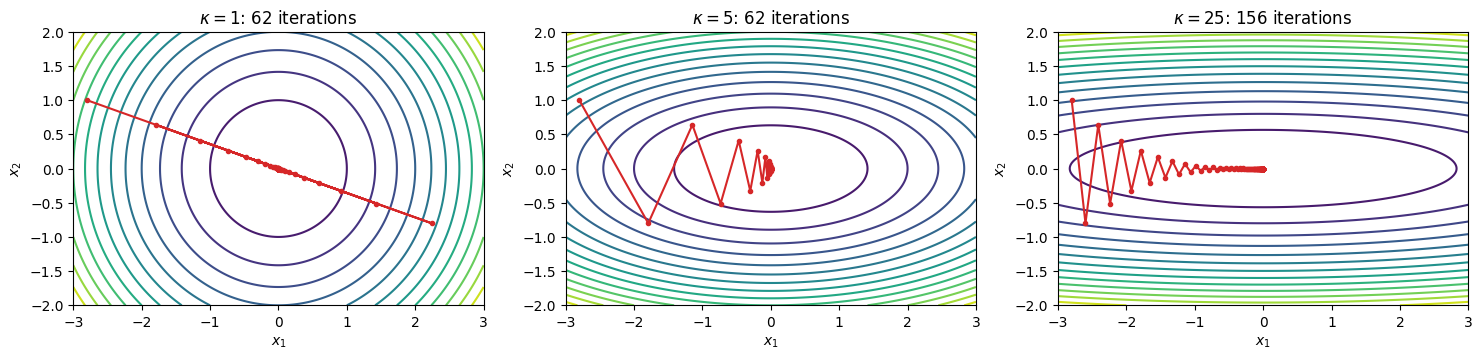

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
xx1, xx2 = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-2, 2, 300))

for ax, lam in zip(axes, [1, 5, 25]):
    A = np.diag([1.0, lam])
    f = lambda x: 0.5 * x @ A @ x
    grad_f = lambda x: A @ x

    x_hist, f_hist, grad_norm = gradient_descent(f, grad_f, np.array([-2.8, 1.0]),
                                                 alpha=1.8 / lam, maxit=1000)

    ax.contour(xx1, xx2, 0.5 * (xx1**2 + lam * xx2**2), levels=15, cmap="viridis")
    ax.plot(x_hist[:, 0], x_hist[:, 1], 'o-', color="tab:red", ms=3)
    ax.set_title(rf"$\kappa = {lam}$: {len(x_hist) - 1} iterations")
    ax.set_aspect("equal")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
plt.show()

When $\kappa = 1$, the level sets are circles, the gradient points exactly toward the minimum, and GD moves along a straight line toward it. When $\kappa$ grows, the step size must be small to avoid divergence along the "steep" direction $x_2$, which makes the progress along the "flat" direction $x_1$ very slow. As a consequence, the iterates **zig-zag** across the narrow valley, and the number of iterations grows (proportionally to $\kappa$).

```{note}
Ill-conditioning is one of the main issues when training Neural Networks, whose loss functions typically have directions with very different curvatures. As we will see in the last chapter, the **Adam** optimizer has been designed (also) to mitigate this problem. A simple way to improve the conditioning, as we will see, is to **normalize** the input data.
```

### Test 2: Constant step size vs. backtracking

We now consider the **Rosenbrock function**, a classical (non-convex) benchmark for optimization algorithms:

$$
f(x) = 100(x_2 - x_1^2)^2 + (1-x_1)^2,
$$

whose global minimum is $x^* = (1, 1)$, located at the bottom of a long, narrow, curved valley. Its gradient is

$$
\nabla f(x) = \begin{bmatrix} -400 x_1 (x_2 - x_1^2) - 2(1 - x_1) \\ 200 (x_2 - x_1^2) \end{bmatrix}.
$$

In [4]:
def f(x):
    return 100 * (x[1] - x[0]**2)**2 + (1 - x[0])**2

def grad_f(x):
    return np.array([-400 * x[0] * (x[1] - x[0]**2) - 2 * (1 - x[0]),
                     200 * (x[1] - x[0]**2)])

x0 = np.array([-1.5, 2.0])
x_const, f_const, g_const = gradient_descent(f, grad_f, x0, alpha=1e-3, maxit=20000)
x_back, f_back, g_back = gradient_descent(f, grad_f, x0, alpha="backtracking", maxit=20000)

print(f"Constant step: x = {x_const[-1]}, iterations = {len(x_const) - 1}")
print(f"Backtracking:  x = {x_back[-1]}, iterations = {len(x_back) - 1}")

Constant step: x = [0.99888354 0.99776385], iterations = 15403
Backtracking:  x = [1.00039244 1.00078739], iterations = 10012


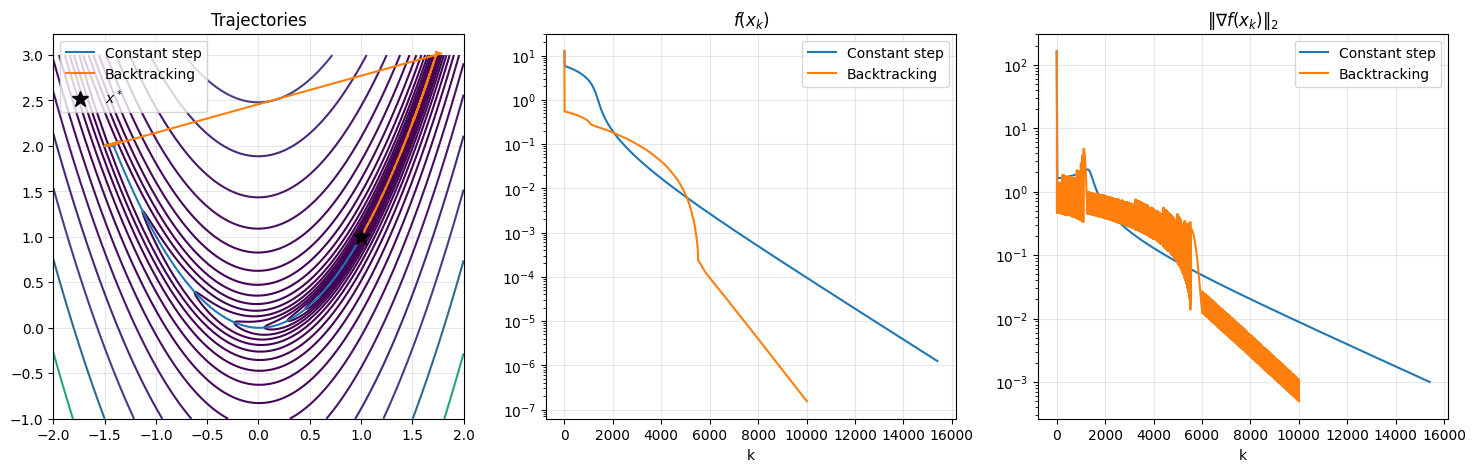

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Trajectories
xx1, xx2 = np.meshgrid(np.linspace(-2, 2, 400), np.linspace(-1, 3, 400))
axes[0].contour(xx1, xx2, 100 * (xx2 - xx1**2)**2 + (1 - xx1)**2,
                levels=np.logspace(-1, 3.5, 20), cmap="viridis")
axes[0].plot(x_const[:, 0], x_const[:, 1], '-', label="Constant step")
axes[0].plot(x_back[:, 0], x_back[:, 1], '-', label="Backtracking")
axes[0].plot(1, 1, 'k*', ms=12, label="$x^*$")
axes[0].set_title("Trajectories")
axes[0].legend()

# Objective function and gradient norm
axes[1].semilogy(f_const, label="Constant step")
axes[1].semilogy(f_back, label="Backtracking")
axes[1].set_title("$f(x_k)$")
axes[1].set_xlabel("k")
axes[1].legend()

axes[2].semilogy(g_const, label="Constant step")
axes[2].semilogy(g_back, label="Backtracking")
axes[2].set_title(r"$\|\nabla f(x_k)\|_2$")
axes[2].set_xlabel("k")
axes[2].legend()

for ax in axes:
    ax.grid(alpha=0.3)
plt.show()

Note that the objective function decreases monotonically, while the gradient norm does not: GD is only guaranteed to decrease $f$, not $\|\nabla f\|_2$. Moreover, backtracking allows to use much larger step sizes when the function is flat (at the bottom of the valley), resulting in a faster convergence, even if each iteration is more expensive.

### Test 3: Non-convexity and the initial iterate

Finally, consider the one-dimensional non-convex function

$$
f(x) = x^4 - 3x^2 + x,
$$

which has two local minima, only one of which is global. Let's run GD from different initial iterates.

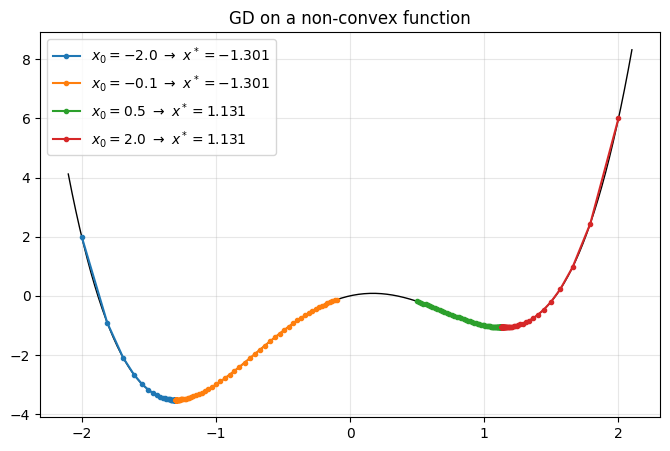

In [6]:
f = lambda x: x**4 - 3 * x**2 + x
grad_f = lambda x: 4 * x**3 - 6 * x + 1

xx = np.linspace(-2.1, 2.1, 300)
plt.figure(figsize=(8, 5))
plt.plot(xx, f(xx), 'k', lw=1)
for x0 in [-2.0, -0.1, 0.5, 2.0]:
    x_hist, f_hist, _ = gradient_descent(f, grad_f, np.array([x0]), alpha=0.01)
    plt.plot(x_hist[:, 0], f_hist, 'o-', ms=3, label=f"$x_0 = {x0}$ $\\to$ $x^* = {x_hist[-1, 0]:.3f}$")
plt.legend()
plt.grid(alpha=0.3)
plt.title("GD on a non-convex function")
plt.show()

As expected, depending on the initial iterate, GD converges to a different local minimum. For a Neural Network, this means that **different random initializations lead to different trained networks**. Luckily, it has been observed that, for large Neural Networks, most of the local minima have a similar (low) value of the loss, so this is less problematic than it may seem.

## Back to Neural Networks: training with Gradient Descent

We are now ready to go back to the problem we left open at the end of the previous chapter: training the MLP classifier on the triangle dataset. Here, the optimization variable is $x = \Theta = \{ W^l, b^l \}_{l=1}^L$, the objective function is the Cross-Entropy loss $f = \mathcal{L}$, and its gradient is computed by backpropagation. The GD update reads:

$$
W^l \leftarrow W^l - \alpha \nabla_{W^l} \mathcal{L}(\Theta), \qquad b^l \leftarrow b^l - \alpha \nabla_{b^l} \mathcal{L}(\Theta), \qquad l = 1, \dots, L.
$$

We copy here the code from the previous chapter (expand the cell below to see it).

In [7]:
# ---- Code from the previous chapter ----
def relu(z):
    return np.maximum(0, z)

def relu_prime(z):
    return (z > 0).astype(float)

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def init_params(sizes, seed=0):
    rng = np.random.default_rng(seed)
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        W = rng.normal(0, np.sqrt(2 / n_in), (n_out, n_in))
        b = np.zeros(n_out)
        params.append([W, b])
    return params

def forward(params, X):
    H = X
    cache = [(None, X)]
    for l, (W, b) in enumerate(params):
        Z = H @ W.T + b
        H = softmax(Z) if l == len(params) - 1 else relu(Z)
        cache.append((Z, H))
    return H, cache

def cross_entropy(Y_hat, Y):
    return -np.mean(np.sum(Y * np.log(Y_hat + 1e-12), axis=1))

def backward(params, cache, Y):
    N = Y.shape[0]
    grads = [None] * len(params)
    Delta = (cache[-1][1] - Y) / N
    for l in reversed(range(len(params))):
        W, b = params[l]
        H_prev = cache[l][1]
        grads[l] = [Delta.T @ H_prev, Delta.sum(axis=0)]
        if l > 0:
            Delta = (Delta @ W) * relu_prime(cache[l][0])
    return grads

# ---- The triangle dataset ----
np.random.seed(0)
N = 1000
X = np.random.uniform(-1.5, 1.5, (N, 2))

def inside_triangle(X):
    x1, x2 = X[:, 0], X[:, 1]
    return ((x2 + 0.7 >= 0) & (1.7 * x1 - x2 + 1 >= 0) & (-1.7 * x1 - x2 + 1 >= 0)).astype(int)

y = inside_triangle(X)
Y = np.eye(2)[y]

Since the parameters are stored as a list of `[W, b]` pairs, we write a GD training loop which updates each of them. At each iteration, we also store the loss and the accuracy on the training set.

In [8]:
def accuracy(Y_hat, y):
    return np.mean(Y_hat.argmax(axis=1) == y)

def train_gd(params, X, Y, y, alpha=0.1, maxit=1000):
    loss_hist, acc_hist = [], []
    for k in range(maxit):
        # Forward and backward pass on the WHOLE dataset
        Y_hat, cache = forward(params, X)
        grads = backward(params, cache, Y)

        # GD update for each parameter
        for (W, b), (dW, db) in zip(params, grads):
            W -= alpha * dW
            b -= alpha * db

        loss_hist.append(cross_entropy(Y_hat, Y))
        acc_hist.append(accuracy(Y_hat, y))
    return params, np.array(loss_hist), np.array(acc_hist)

Let's train the network for different values of the step size $\alpha$.

alpha = 0.01: final loss = 0.1843, final accuracy = 92.70% (time: 0.89s)


alpha = 0.1: final loss = 0.0262, final accuracy = 99.80% (time: 0.92s)


alpha = 0.5: final loss = 0.0067, final accuracy = 100.00% (time: 0.92s)


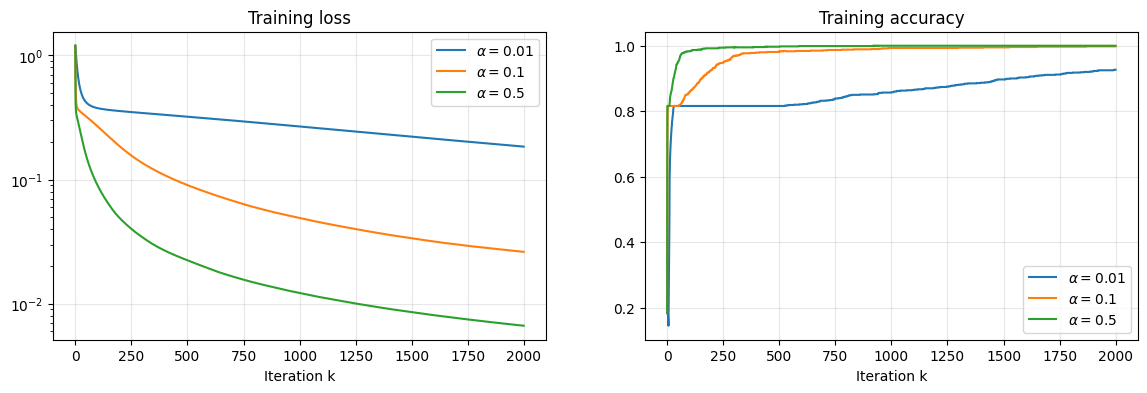

In [9]:
import time

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for alpha in [0.01, 0.1, 0.5]:
    params = init_params([2, 16, 16, 2], seed=0)
    start = time.time()
    params, loss_hist, acc_hist = train_gd(params, X, Y, y, alpha=alpha, maxit=2000)
    print(f"alpha = {alpha}: final loss = {loss_hist[-1]:.4f}, final accuracy = {acc_hist[-1]*100:.2f}%"
          f" (time: {time.time() - start:.2f}s)")

    axes[0].semilogy(loss_hist, label=rf"$\alpha = {alpha}$")
    axes[1].plot(acc_hist, label=rf"$\alpha = {alpha}$")

axes[0].set_title("Training loss")
axes[1].set_title("Training accuracy")
for ax in axes:
    ax.set_xlabel("Iteration k")
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()

The behavior is exactly the one predicted by the theory: with a small step size, the loss decreases very slowly, while larger step sizes lead to faster convergence. Let's look at the decision boundary learned by the network with the largest step size.

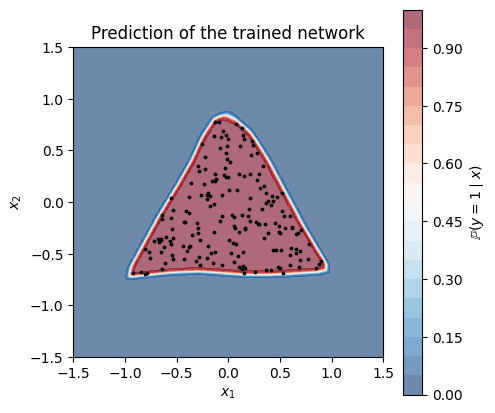

In [10]:
xx1, xx2 = np.meshgrid(np.linspace(-1.5, 1.5, 300), np.linspace(-1.5, 1.5, 300))
grid = np.stack([xx1.ravel(), xx2.ravel()], axis=1)
P_grid, _ = forward(params, grid)

plt.figure(figsize=(5, 5))
plt.contourf(xx1, xx2, P_grid[:, 1].reshape(xx1.shape), levels=20, cmap="RdBu_r", alpha=0.6)
plt.colorbar(label=r"$\mathbb{P}(y = 1 \mid x)$")
plt.scatter(X[y == 1, 0], X[y == 1, 1], s=3, c="k")
plt.title("Prediction of the trained network")
plt.gca().set_aspect("equal")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.show()

The network learned, by itself, to recognize the triangle, and we never told it that the region was a triangle!

## Limitations of Gradient Descent

Despite its simplicity and its nice theoretical properties, Gradient Descent has several drawbacks when applied to the training of Machine Learning models:

1. **Computationally expensive**: computing the gradient requires a forward and a backward pass over the **entire** dataset at every iteration. Here, we used $N = 1000$ datapoints in $\mathbb{R}^2$, but realistic datasets contain millions of high-dimensional datapoints.
2. **Learning rate sensitivity**: too small $\implies$ slow convergence, too large $\implies$ oscillations or divergence. Backtracking solves this issue, but it requires additional evaluations of the loss on the whole dataset.
3. **Local minima, saddle points, and plateaus** in non-convex landscapes.
4. **Ill-conditioning** causes slow progress and zig-zagging.

The first limitation is, by far, the most important in practice, and it is the topic of the next chapter, where we introduce **Stochastic Gradient Descent (SGD)**.

> **Exercise:** Repeat the training of the MLP on the triangle dataset with $N = 100, 1000, 10000, 100000$ datapoints, measuring the time required for each iteration of GD. How does it scale with $N$?

> **Exercise:** Implement a GD training loop for the MLP with backtracking. Compare the number of iterations and the total time required to reach a training loss of $10^{-1}$ with the ones of the constant step size.